In [ ]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import pandas as pd
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = 'glpk'

In [3]:
with open('../../FBAsolution/M9_sufficient_20_40_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

with open('../../FBAsolution/M9_sufficient_400_40_proteome_weakbg.pkl', 'rb') as pickle_file:
    data3 = pickle.load(pickle_file)
    all_total_nutrient_count3 = data3['all_total_nutrient_count']
    all_total_intake3 = data3['all_total_intake']
    all_growth_rate3 = data3['all_growth_rate']
    all_random_medium3 = data3['all_random_medium']
    all_met_flux3 = data3['all_met_flux']
    del data3
    
with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data4 = pickle.load(pickle_file)
    all_total_nutrient_count4 = data4['all_total_nutrient_count']
    all_total_intake4 = data4['all_total_intake']
    all_growth_rate4 = data4['all_growth_rate']
    all_random_medium4 = data4['all_random_medium']
    all_met_flux4 = data4['all_met_flux']
    del data4

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

with open("origin_TL_3e-3.pkl", "rb") as f:
    origin_TL_1, origin_TL_2, origin_TL_3, origin_TL_4 = pickle.load(f)

data = np.load("efficient_edges_3e-3.npz")
frequency = data["frequency"]
emerge = data["emerge"]
disappear = data["disappear"]

In [ ]:
efficiency = frequency * (disappear - emerge + 20)
efficiency_sorted_indices = np.dstack(np.unravel_index(np.argsort(efficiency.ravel())[::-1], efficiency.shape))[0]
efficient_edges = [(a[0], a[1]) for a in efficiency_sorted_indices[:10]]

edge_data = []
for (r, c) in efficient_edges:
    edge_data.append({
        "edge": f"({r}, {c})",
        "frequency": int(frequency[r, c]),
        "disappear": int(disappear[r, c]),
        "emerge": int(emerge[r, c])
    })

df_edges = pd.DataFrame(edge_data)

,edge,frequency,disappear,emerge
0,"(1, 7)",47,116,72
1,"(1, 12)",69,49,29
2,"(9, 19)",105,3,0
3,"(11, 12)",112,0,0
4,"(13, 12)",112,0,0
5,"(13, 19)",112,0,0
6,"(2, 19)",112,0,0
7,"(9, 12)",111,0,0
8,"(7, 11)",56,96,79
9,"(14, 19)",108,0,1


In [12]:
def summary_origin_TL(origin_TL, total_met_flux):
    summary = []

    for j in range(len(origin_TL)):
        if len(origin_TL[j]) == 0:
            continue

        _, _, matrix, _, gr = origin_TL[j]
        matrix = matrix.tocsr()
        binary = (matrix != 0).astype(int)
        coo = binary.tocoo()
        edges = set(zip(coo.row, coo.col))

        n_efficient = sum(1 for e in edges if e in efficient_edges)
        #n_inefficient = sum(1 for e in edges if e in inefficient_edges)
        n_edge = sum(1 for e in edges)

        total_proteome = sum([abs(value) for key, value in total_met_flux[j]])

        summary.append({
            "efficient": n_efficient,
            #"inefficient": n_inefficient,
            'edge': n_edge,
            "gr": 0 if gr == 0 else gr / total_proteome * 1000
        })

    df_origin_summary = pd.DataFrame(summary)

    return df_origin_summary


def summary_origin_TL_wo_norm(origin_TL, total_met_flux):
    summary = []

    for j in range(len(origin_TL)):
        if len(origin_TL[j]) == 0:
            continue

        _, _, matrix, _, gr = origin_TL[j]
        matrix = matrix.tocsr()
        binary = (matrix != 0).astype(int)
        coo = binary.tocoo()
        edges = set(zip(coo.row, coo.col))

        n_efficient = sum(1 for e in edges if e in efficient_edges)
        #n_inefficient = sum(1 for e in edges if e in inefficient_edges)
        n_edge = sum(1 for e in edges)

        total_proteome = sum([abs(value) for key, value in total_met_flux[j]])

        summary.append({
            "efficient": n_efficient,
            #"inefficient": n_inefficient,
            'edge': n_edge,
            "gr": 0 if gr == 0 else gr
        })

    df_origin_summary = pd.DataFrame(summary)

    return df_origin_summary

import pandas as pd

def efficient_edges_per_graph(origin_TL):
    summary = []

    for j in range(len(origin_TL)):
        if len(origin_TL[j]) == 0:
            continue

        _, _, matrix, _, gr = origin_TL[j]
        matrix = matrix.tocsr()
        binary = (matrix != 0).astype(int)
        coo = binary.tocoo()
        edges = set(zip(coo.row, coo.col))

        vec = [1 if e in edges else 0 for e in efficient_edges]

        summary.append(vec)

    return summary

In [13]:
summary_1 = summary_origin_TL(origin_TL_1, all_met_flux[0])
summary_3 = summary_origin_TL(origin_TL_3, all_met_flux3[0])

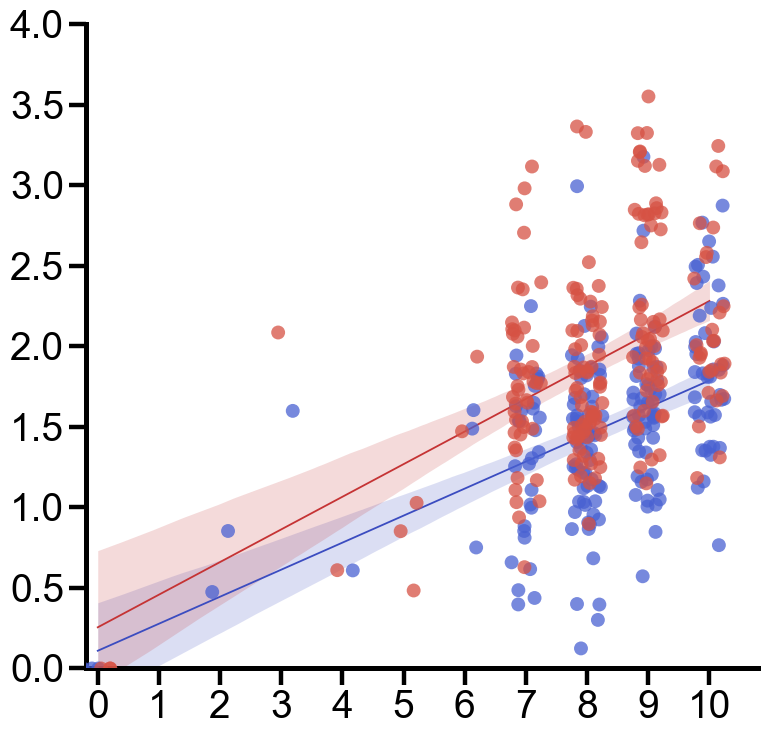

In [ ]:
set_panel_style(scale=4)

cmap = plt.get_cmap("coolwarm")
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

set_color_1     = colors[0]    # line+band for dataset 1
scatter_color_1 = colors[1]    # points for dataset 1
set_color_2     = colors[19]   # line+band for dataset 2
scatter_color_2 = colors[18]   # points for dataset 2

# ----- dataset 1 (summary_1) -----
x1 = summary_1["efficient"].to_numpy(dtype=float)
y1 = summary_1["gr"].to_numpy(dtype=float)
m1 = np.isfinite(x1) & np.isfinite(y1)
x1, y1 = x1[m1], y1[m1]

m, b = np.polyfit(x1, y1, deg=1)
xg1 = np.linspace(x1.min(), x1.max(), 200)
yg1 = m * xg1 + b

B = 2000
rng = np.random.default_rng(0)
Yhat1 = np.empty((B, xg1.size))
n1 = x1.size
for i in range(B):
    idx = rng.integers(0, n1, n1)
    m_i, b_i = np.polyfit(x1[idx], y1[idx], deg=1)
    Yhat1[i] = m_i * xg1 + b_i
lo1, hi1 = np.percentile(Yhat1, [2.5, 97.5], axis=0)

# ----- dataset 2 (summary_3) -----
x2 = summary_3["efficient"].to_numpy(dtype=float)
y2 = summary_3["gr"].to_numpy(dtype=float)
m2 = np.isfinite(x2) & np.isfinite(y2)
x2, y2 = x2[m2], y2[m2]

m, b = np.polyfit(x2, y2, deg=1)
xg2 = np.linspace(x2.min(), x2.max(), 200)
yg2 = m * xg2 + b

Yhat2 = np.empty((B, xg2.size))
n2 = x2.size
for i in range(B):
    idx = rng.integers(0, n2, n2)
    m_i, b_i = np.polyfit(x2[idx], y2[idx], deg=1)
    Yhat2[i] = m_i * xg2 + b_i
lo2, hi2 = np.percentile(Yhat2, [2.5, 97.5], axis=0)

df_pts = pd.DataFrame({
    "efficient": np.concatenate([x1, x2]).astype(int), 
    "gr":        np.concatenate([y1, y2]),
    "group":     (["G1"] * len(x1)) + (["G2"] * len(x2))
})

fig, ax = plt.subplots(figsize=(8, 8))

x_order = list(range(0, 11))

sns.stripplot(
    data=df_pts, x="efficient", y="gr", hue="group",
    order=x_order,  
    jitter=0.25,
    dodge=False,
    size=10,
    alpha=0.75,
    edgecolor="none",
    palette={"G1": scatter_color_1, "G2": scatter_color_2},
    ax=ax
)

leg = ax.get_legend()
if leg is not None:
    leg.remove()

ax.plot(xg1, yg1, linewidth=1.3, color=set_color_1, alpha=1)
ax.fill_between(xg1, lo1, hi1, color=set_color_1, alpha=0.18, linewidth=0)

ax.plot(xg2, yg2, linewidth=1.3, color=set_color_2, alpha=1)
ax.fill_between(xg2, lo2, hi2, color=set_color_2, alpha=0.18, linewidth=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(0, 4)

ax.set_xticks(range(len(x_order)))
ax.set_xticklabels([str(v) for v in x_order])

ax.set_xlim(-0.2, len(x_order) - 0.2)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
#fig.savefig("Figure5F.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.close(fig)

In [15]:
pearson_ci(x1, y1), pearson_ci(x2, y2)

({'r': 0.5119479281850432,
  'p': 4.3148025611741675e-15,
  'ci_low': 0.40319927571977526,
  'ci_high': 0.6064383834738492,
  'n': 205},
 {'r': 0.4902468089170821,
  'p': 8.580782195172642e-14,
  'ci_low': 0.3786498636189986,
  'ci_high': 0.5877932940050447,
  'n': 205})